# Klasifikacija slika - American Sign Language Dataset

Kao u prošlom *notebook*-u, proći ćemo kroz korake pripreme podataka, kreiranja modela i treninga modela. Koristićemo novi skup podataka [*American Sign Language*](http://www.asl.gs/) (ASL).

ASL skup podataka sadrži 26 slova. Dva od ovih slova (j i z) zahtevaju gest (pokret), pa nisu uključena u ovaj skup podataka.

ASL je dostupan preko [Kaggle](https://www.kaggle.com/) platforme koja sadrži mnogo korisnih skupova podataka i drugih resursa za mašinsko učenje. Na primer, uz skupove podataka postoje "kerneli" koji nalikuju ovim *notebook*-ovima. Kaggle takođe organizuje takmičenja iz mašinskog učenja.

## Učitavanje podataka

ASL skup podataka je u [CSV](https://en.wikipedia.org/wiki/Comma-separated_values) (Comma Separated Values) formatu. Da bismo učitali ovaj skup podataka, koristićemo [Pandas](https://pandas.pydata.org/) biblioteku - pomoću njene `read_csv` metode ćemo učitati CSV skup podataka u [DataFrame](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html) format.

In [ ]:
import pandas as pd

train_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_valid.csv")

### Analiza i priprema podataka

Pomoću [`head`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html) metode ćemo ispisati prvih nekoliko redova trening skupa podataka (DataFrame objekta). Vidimo da svaki red ima `label` kolonu i 784 vrednosti koje odgovaraju vrednostima piksela na slici (kao što je bio slučaj kod MNIST skupa podataka). Obratite pažnju da je `label` kolona  numerička (a ne slova alfabeta).

In [ ]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,12,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


Kao kod MNIST-a, izdvojićemo labele u `y_train` i `y_valid` varijable. Kreiramo ove varijable i zatim brišemo odgovarajuće kolone iz originalnog DataFrame-a:

In [ ]:
y_train = train_df['label']
y_test = test_df['label']
del train_df['label']
del test_df['label']

Preostale kolone (vrednosti intenziteta piksela) ćemo sačuvati u `x_train` i `x_valid` varijablama.

In [ ]:
x_train = train_df.values
x_test = test_df.values

Trening skup: 27 455 slike, svaka opisana sa 784 vrednosti piksela:

In [ ]:
x_train.shape

(27455, 784)

Odgovarajuće labele trening skupa:

In [ ]:
y_train.shape

(27455,)

Test skup: 7 172 slike:

In [ ]:
x_test.shape

(7172, 784)

Odgovarajuće labele test skupa:

In [ ]:
y_test.shape

(7172,)

Možemo vizualizovati slike pomoću [matplotlib](https://matplotlib.org/) biblioteke. Da bismo ovo uradili, moramo *reshape*-ovati podatke iz 1D niza nazad u 2D niz od 28 x 28 piksela:

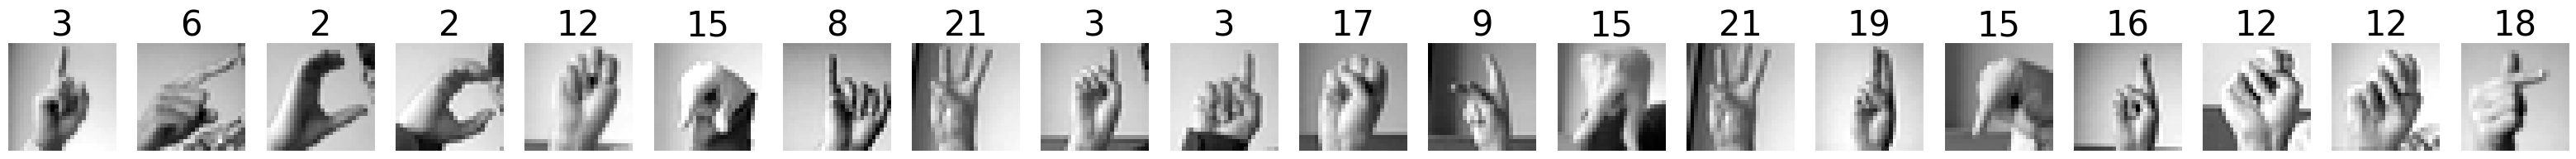

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,40))

num_images = 20
for i in range(num_images):
    row = x_train[i]
    label = y_train[i]

    image = row.reshape(28,28)
    plt.subplot(1, num_images, i+1)
    plt.title(label, fontdict={'fontsize': 30})
    plt.axis('off')
    plt.imshow(image, cmap='gray')

### Normalizacija:

Pre normalizacije:

In [ ]:
x_train.min()

0

In [ ]:
x_train.max()

255

Nakon normalizacije:

In [ ]:
x_train = x_train/255
x_test = x_test/255

In [ ]:
x_train.min()

0.0

In [ ]:
x_train.max()

1.0

### Enkodiranje labela:

Pre enkodiranja:

In [ ]:
y_train[0:3]

0    3
1    6
2    2
Name: label, dtype: int64

Koristimo [keras.utils.to_categorical](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical) metodu:

In [ ]:
import tensorflow.keras as keras
num_classes = 24

y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

Nakon enkodiranja:

In [ ]:
y_train[0:3]

array([[0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

### Podela trening podataka na trening i validacioni skup

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

## Izgradnja modela

Napravićemo model koji ima:
1. Ulazni sloj (784 vrednosti), potpuno povezan (*dense*)
2. Prvi skriveni sloj od 512 neurona sa ReLu aktivacionom funkcijom
3. Drugi skriveni sloj od 512 neurona sa ReLu aktivacionom funkcijom
4. Izlazni sloj (24 neurona - broj klasa), potpuno povezan sa *softmax* aktivacionom funkcijom.

Dokumentacija: [Sequential](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential), [Dense](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense).

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()
model.add(Dense(units=512, activation='relu', input_shape=(784,)))
model.add(Dense(units=512, activation='relu'))
model.add(Dense(units=num_classes, activation='softmax'))


In [ ]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 512)               401920    
                                                                 
 dense_4 (Dense)             (None, 512)               262656    
                                                                 
 dense_5 (Dense)             (None, 24)                12312     
                                                                 
Total params: 676888 (2.58 MB)
Trainable params: 676888 (2.58 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Kompajliramo model metodom [compile](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential#compile), koristeći `categorical_crossentropy` kao funkciju gubitka. Napredak modela pratićemo kroz `F1` metriku:

In [ ]:
from tensorflow.keras import backend as K

def f1_score(y_true, y_pred):
    # Calculating Precision and Recall
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))

    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())

    # Calculating F1 Score
    f1_val = 2*(precision*recall)/(precision+recall+K.epsilon())

    return f1_val

In [ ]:
model.compile(loss='categorical_crossentropy', metrics=[f1_score])

## Treniranje modela

Iskoristićemo [fit](https://www.tensorflow.org/api_docs/python/tf/keras/Model#fit) metodu da treniramo model u 20 epoha:

In [ ]:
history = model.fit(x=x_train, y=y_train, epochs=20, verbose=1, validation_data=(x_val, y_val))

Epoch 1/20
687/687 [==============================] - 10s 5ms/step - loss: 2.0840 - f1_score: 0.2272 - val_loss: 1.7947 - val_f1_score: 0.3972
Epoch 2/20
687/687 [==============================] - 3s 4ms/step - loss: 1.1152 - f1_score: 0.5956 - val_loss: 1.3482 - val_f1_score: 0.5615
Epoch 3/20
687/687 [==============================] - 3s 5ms/step - loss: 0.7257 - f1_score: 0.7525 - val_loss: 0.5052 - val_f1_score: 0.8238
Epoch 4/20
687/687 [==============================] - 4s 6ms/step - loss: 0.4999 - f1_score: 0.8344 - val_loss: 1.2359 - val_f1_score: 0.6633
Epoch 5/20
687/687 [==============================] - 3s 5ms/step - loss: 0.3578 - f1_score: 0.8859 - val_loss: 0.7999 - val_f1_score: 0.8151
Epoch 6/20
687/687 [==============================] - 3s 4ms/step - loss: 0.3008 - f1_score: 0.9117 - val_loss: 0.0537 - val_f1_score: 0.9885
Epoch 7/20
687/687 [==============================] - 3s 4ms/step - loss: 0.2408 - f1_score: 0.9313 - val_loss: 0.0616 - val_f1_score: 0.9784
Epoch

Vizuelizacija trening i validacione tačnosti kroz epohe:

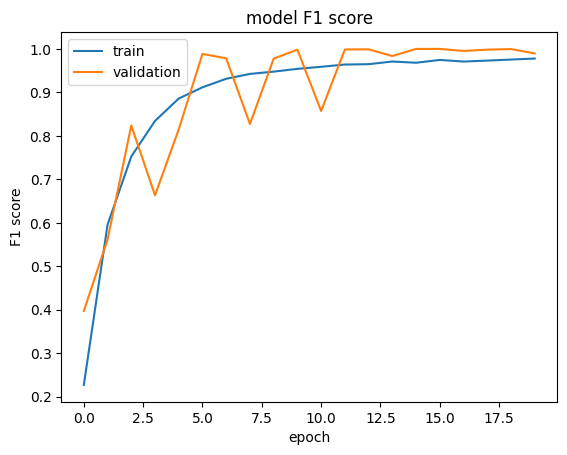

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['f1_score'])
plt.plot(history.history['val_f1_score'])
plt.title('model F1 score')
plt.ylabel('F1 score')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [ ]:
# Evaluate the model on test data
test_loss, test_f1_score = model.evaluate(x_test, y_test, verbose=0)

print("F1 Score on Test Data:", test_f1_score)

F1 Score on Test Data: 0.7852234840393066


Podsećanja radi, sa HOG+SVM pristupom smo dobili:
Train F-measure:  0.9999544724678913
Train F-measure:  0.6253860344087738

## Analiza rezultata

Vidimo da je tačnost na trening skupu dostigla relativno visok nivo. Međutim, tačnost na test skupu je značajno manja. Zašto se ovo desilo?